# Z3003 Data Mining Project
## Bank Marketing Subscription Prediction

**Research question:** Can customer characteristics and previous-campaign information help identify clients who are more likely to subscribe to a term deposit?

**Dataset:** UCI Bank Marketing, legacy `bank-full.csv` (45,211 observations and 17 columns).

**Mining technique:** Decision Tree classification.

**Target:** `y` — whether the client subscribed (`yes` / `no`).

**Prediction setting:** The model is intended to support decisions before a marketing call. Therefore, `duration` is excluded because the call duration is only known after the call and would create information leakage.

This notebook proceeds from data understanding and exploratory analysis through preprocessing, modelling, evaluation, interpretation, limitations, and conclusions.

> **Reproducibility:** Keep the original UCI file named `bank-full.csv` in the `bank/` folder beside this notebook (or in one of the locations checked by the loading cell). The raw dataset is not committed to this repository.

In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn scipy

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
   -- ------------------------------------- 0.8/10.9 MB 763.9 kB/s eta 0:00:14
   -- ------------------------------------- 0.8/10.9 MB 763.9 kB/s eta 0:00:14
   --- ------------------------------------ 1.0/10.9 MB 795.5 kB/s eta 0:00:13
   --- ------------------------------------ 1.0/10.9 MB 795.5 kB/s eta 0:00:13
   ----


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import scipy

print("All required libraries installed successfully.")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

All required libraries installed successfully.
Pandas: 3.1.1
Scikit-learn: 1.9.1


In [6]:
# ============================================================
# Z3003 DATA MINING PROJECT
# BANK MARKETING SUBSCRIPTION PREDICTION
# PHASE 1: DATA LOADING & INITIAL DATA UNDERSTANDING
# ============================================================

# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Consistent visualization style
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

# 2. LOAD DATASET
from pathlib import Path

# Locate bank-full.csv without relying on a personal computer path.
candidate_paths = [
    Path("bank/bank-full.csv"),
    Path("bank-full.csv"),
    Path("data/bank-full.csv"),
    Path("../bank/bank-full.csv"),
    Path("../bank-full.csv"),
]

data_path = next((path for path in candidate_paths if path.exists()), None)

# If the common locations do not work, search the current folder and its parent.
if data_path is None:
    search_roots = [Path.cwd(), Path.cwd().parent]
    for root in search_roots:
        matches = list(root.glob("**/bank-full.csv"))
        if matches:
            data_path = matches[0]
            break

if data_path is None:
    raise FileNotFoundError(
        "Could not find bank-full.csv. Place it in a 'bank' folder beside "
        "this notebook, or update candidate_paths to its location."
    )

print(f"Loading dataset from: {data_path.resolve()}")
df = pd.read_csv(data_path, sep=";")

# 3. BASIC DATASET OVERVIEW
print("=" * 70)
print("DATASET OVERVIEW")
print("=" * 70)

print(f"Dataset dimensions: {df.shape}")
print(f"Number of observations: {df.shape[0]:,}")
print(f"Number of attributes: {df.shape[1]}")

print("\nFIRST FIVE OBSERVATIONS")
display(df.head())

print("\nLAST FIVE OBSERVATIONS")
display(df.tail())

# 4. STRUCTURAL INFORMATION
print("\nDATASET INFORMATION")
df.info()

# 5. ATTRIBUTE DATA TYPES
print("\nATTRIBUTE DATA TYPES")
display(pd.DataFrame({
    "Attribute": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Unique_Values": df.nunique().values
}).sort_values("Attribute").reset_index(drop=True))

# 6. DATA QUALITY ASSESSMENT
print("\nDATA QUALITY ASSESSMENT")

# Actual missing values
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

print("\nACTUAL MISSING VALUES")
display(missing_summary.sort_values(
    "Missing_Percentage", ascending=False
))

# Explicit unknown values
unknown_summary = pd.DataFrame({
    "Unknown_Count": (df == "unknown").sum(),
    "Unknown_Percentage": ((df == "unknown").mean() * 100).round(2)
})

print("\nEXPLICIT 'UNKNOWN' VALUES")
display(unknown_summary.sort_values(
    "Unknown_Percentage", ascending=False
))

# Duplicate records
duplicate_count = df.duplicated().sum()

print(f"\nDuplicate records: {duplicate_count:,}")

# 7. NUMERICAL AND CATEGORICAL ATTRIBUTES
numerical_attributes = df.select_dtypes(include=np.number).columns.tolist()
categorical_attributes = df.select_dtypes(exclude=np.number).columns.tolist()

print("\nNUMERICAL ATTRIBUTES:")
print(numerical_attributes)

print("\nCATEGORICAL ATTRIBUTES:")
print(categorical_attributes)

print("\nINITIAL ASSESSMENT COMPLETED.")

DATASET OVERVIEW
Dataset dimensions: (45211, 17)
Number of observations: 45,211
Number of attributes: 17

FIRST FIVE OBSERVATIONS


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no



LAST FIVE OBSERVATIONS


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no



DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB

ATTRIBUTE DATA TYPES


,Attribute,Data_Type,Unique_Values
0,age,int64,77
1,balance,int64,7168
2,campaign,int64,48
3,contact,str,3
4,day,int64,31
5,default,str,2
6,duration,int64,1573
7,education,str,4
8,housing,str,2
9,job,str,12



DATA QUALITY ASSESSMENT

ACTUAL MISSING VALUES


,Missing_Count,Missing_Percentage
age,0,0.0
job,0,0.0
marital,0,0.0
education,0,0.0
default,0,0.0
balance,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
day,0,0.0



EXPLICIT 'UNKNOWN' VALUES


,Unknown_Count,Unknown_Percentage
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64
age,0,0.00
default,0,0.00
balance,0,0.00
housing,0,0.00
marital,0,0.00
loan,0,0.00



Duplicate records: 0

NUMERICAL ATTRIBUTES:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

CATEGORICAL ATTRIBUTES:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']

INITIAL ASSESSMENT COMPLETED.


NUMERICAL DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0



CATEGORICAL DESCRIPTIVE STATISTICS


,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922



TARGET VARIABLE DISTRIBUTION


,Count,Percentage
y,,
no,39922,88.3
yes,5289,11.7


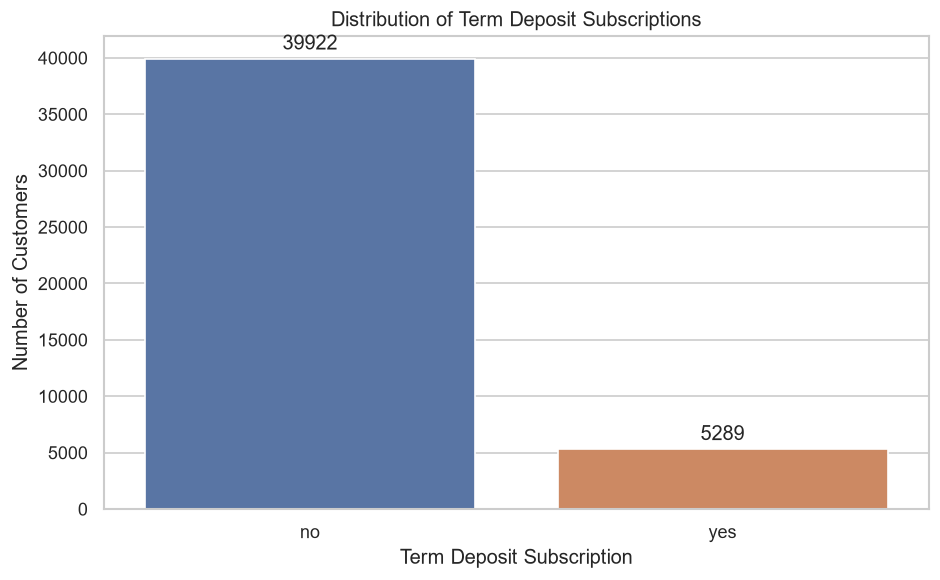

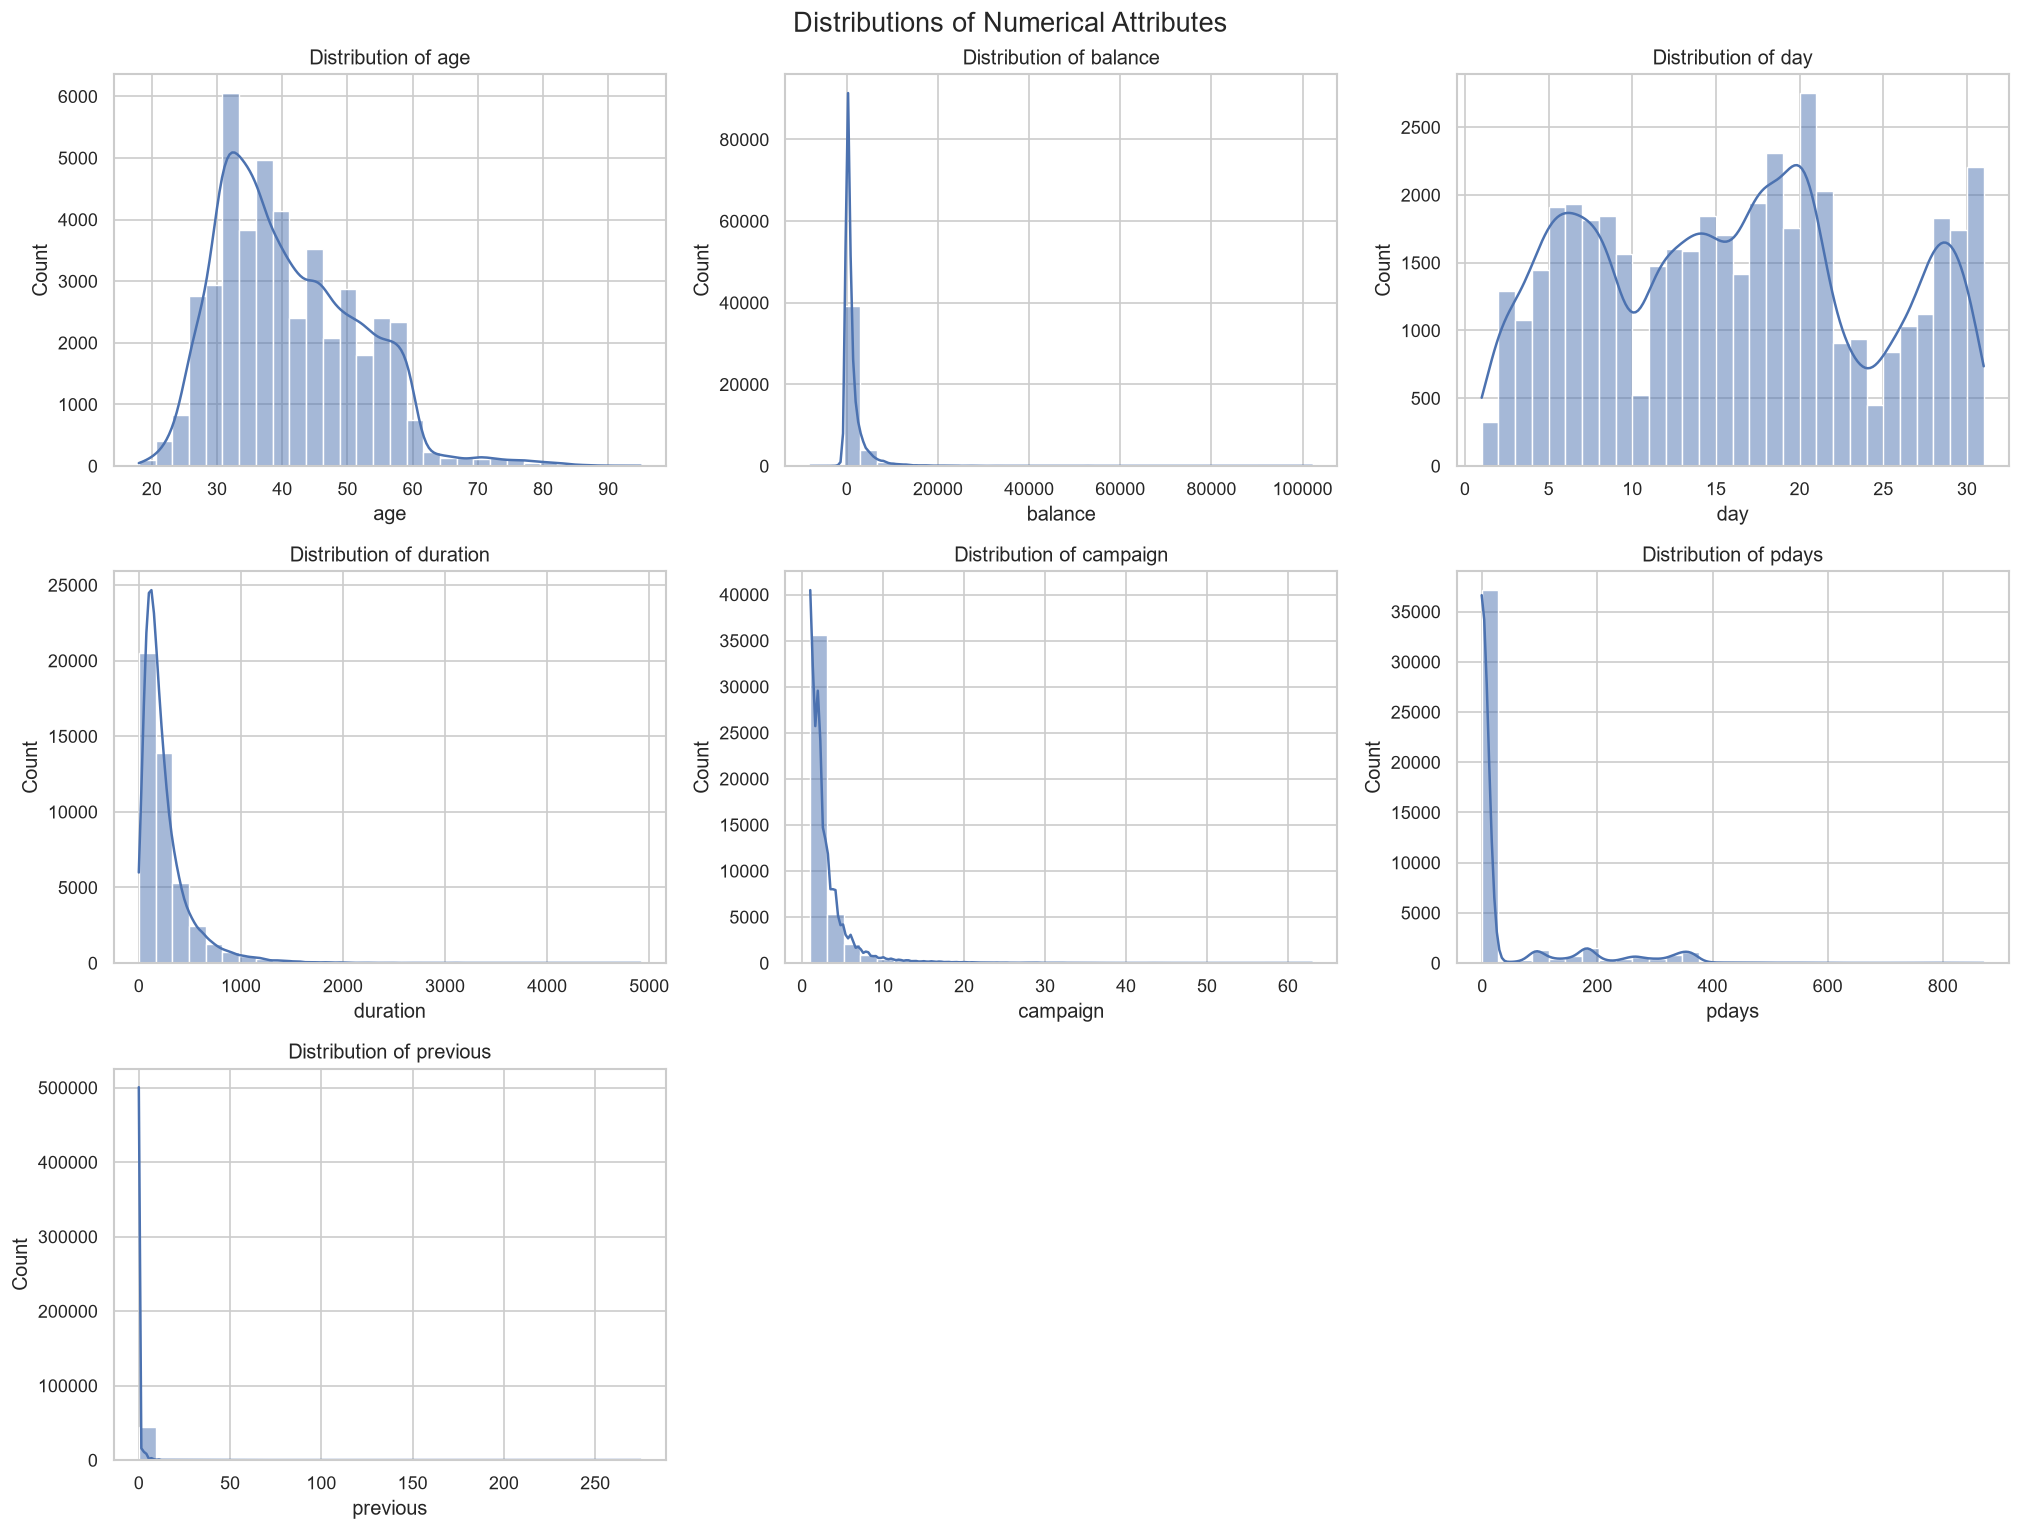

In [7]:
# ============================================================
# PHASE 1: DESCRIPTIVE STATISTICS AND TARGET ANALYSIS
# ============================================================

# Numerical descriptive statistics
print("NUMERICAL DESCRIPTIVE STATISTICS")
display(df[numerical_attributes].describe().T.round(2))

# Categorical descriptive statistics
print("\nCATEGORICAL DESCRIPTIVE STATISTICS")
display(df[categorical_attributes].describe().T)

# Target distribution
target_counts = df["y"].value_counts()
target_percentages = df["y"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})

print("\nTARGET VARIABLE DISTRIBUTION")
display(target_summary)

# Target distribution visualization
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="y", hue="y", legend=False)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.title("Distribution of Term Deposit Subscriptions")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Numerical distribution and outlier inspection
fig, axes = plt.subplots(3, 3, figsize=(17, 13))
axes = axes.flatten()

for i, column in enumerate(numerical_attributes):
    sns.histplot(df[column], kde=True, ax=axes[i], bins=30)
    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)

for j in range(len(numerical_attributes), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Distributions of Numerical Attributes", fontsize=16)
plt.tight_layout()
plt.show()

NUMERICAL OUTLIER ASSESSMENT


,Attribute,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,age,10.5,70.5,487,1.08
1,balance,-1962.0,3462.0,4729,10.46
2,day,-11.5,40.5,0,0.00
3,duration,-221.0,643.0,3235,7.16
4,campaign,-2.0,6.0,3064,6.78
5,pdays,-1.0,-1.0,8257,18.26
6,previous,0.0,0.0,8257,18.26


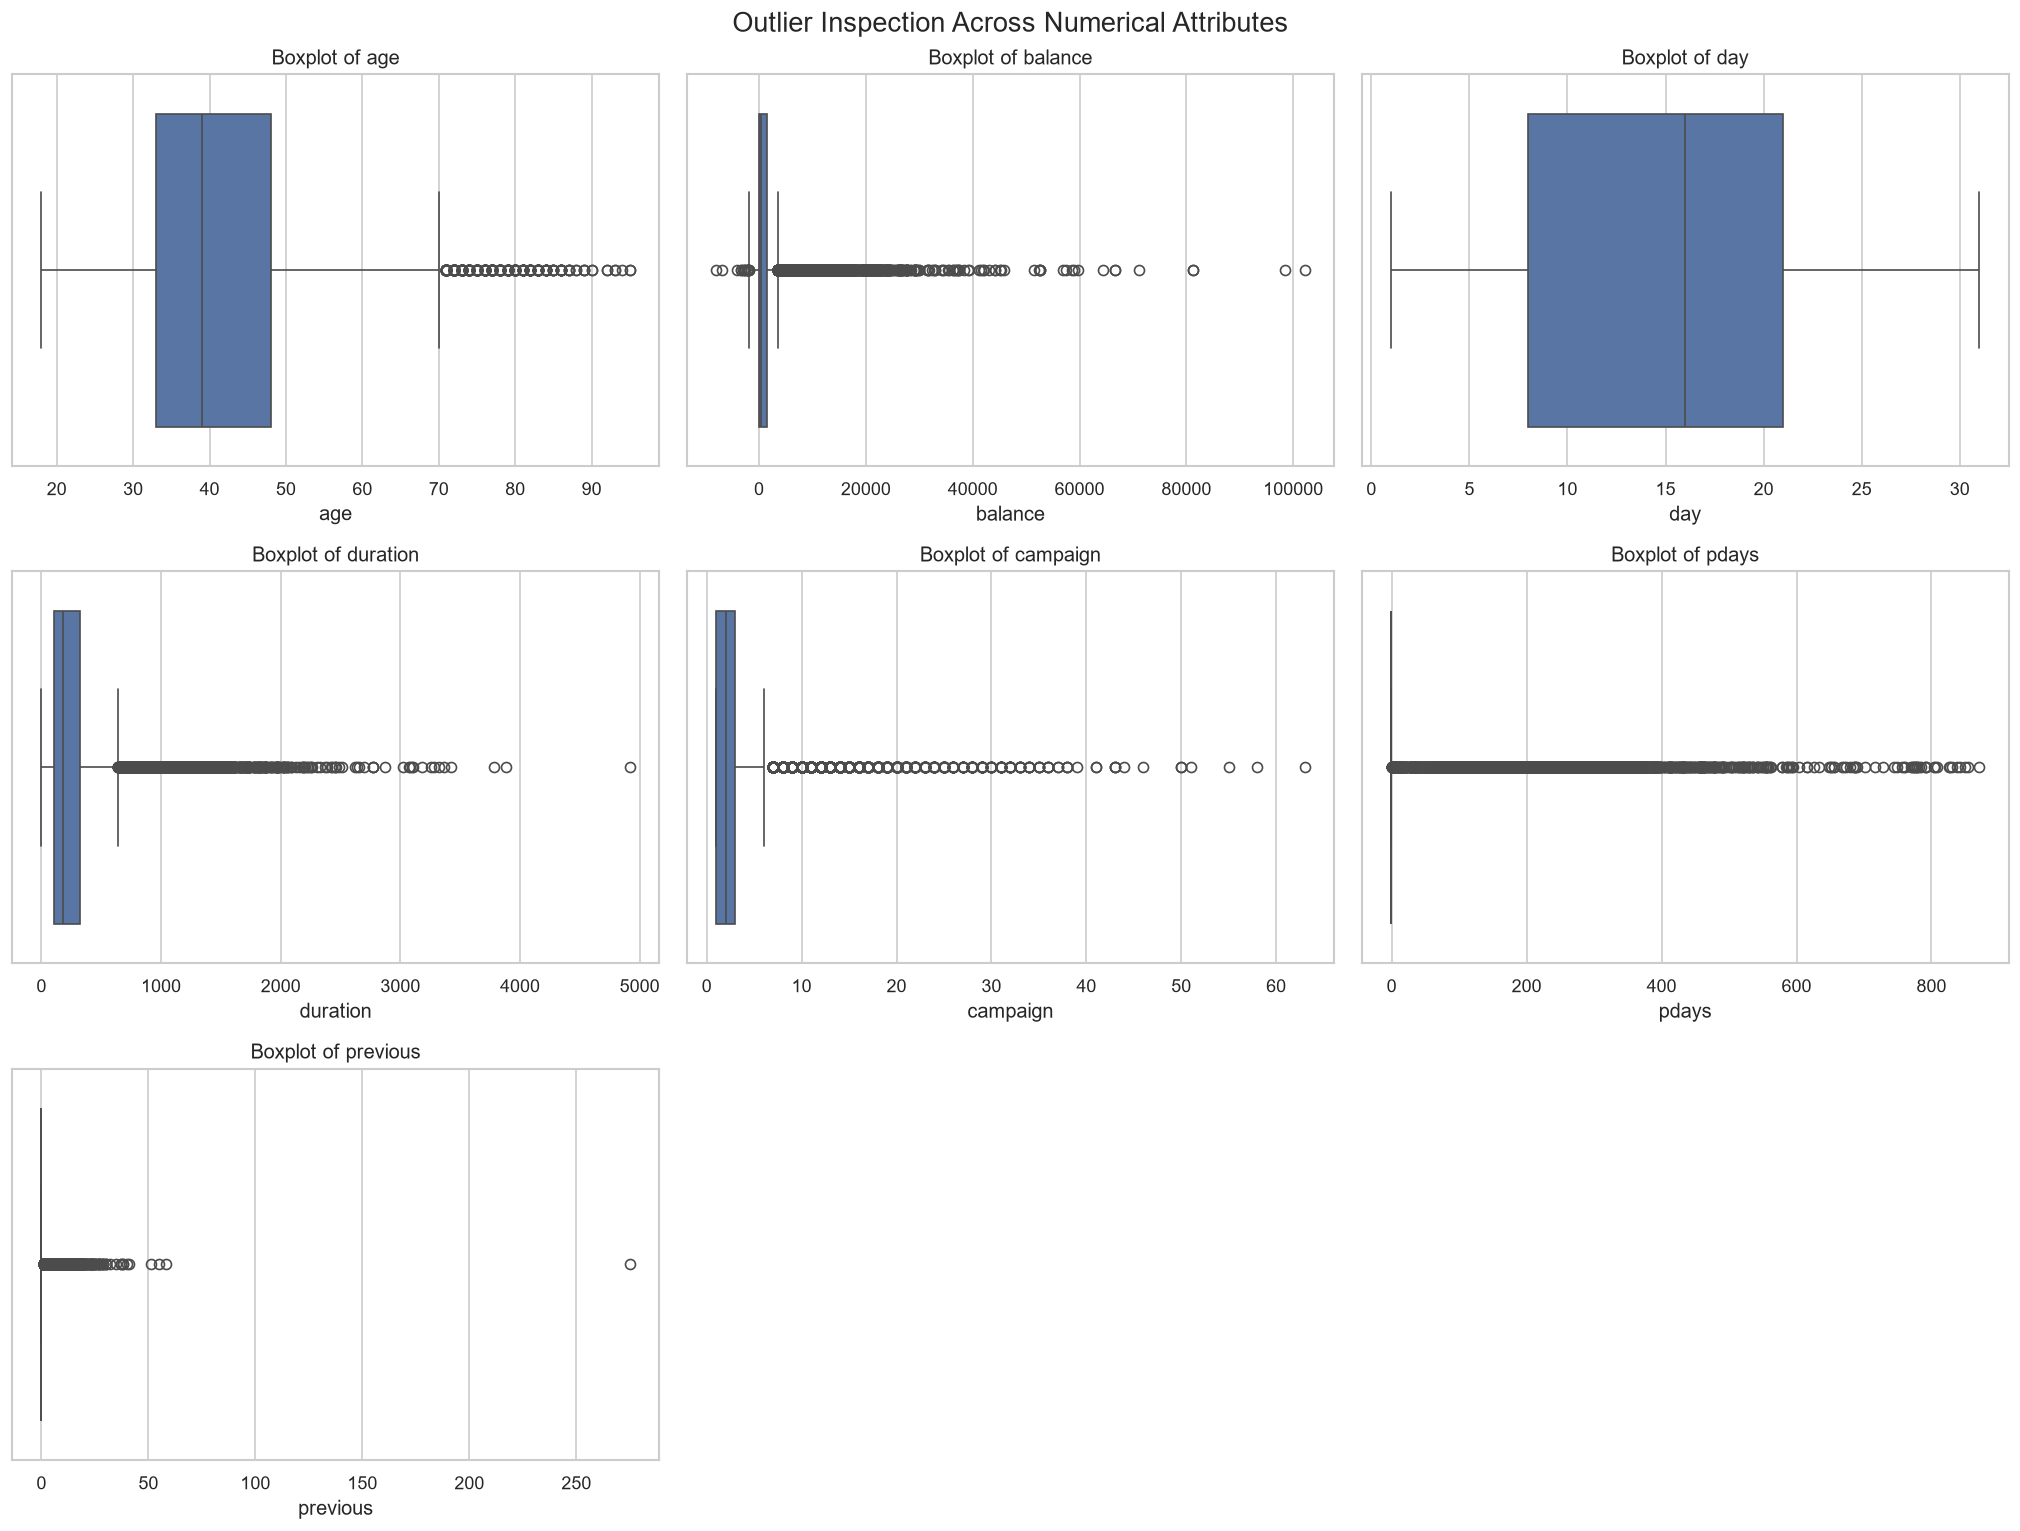

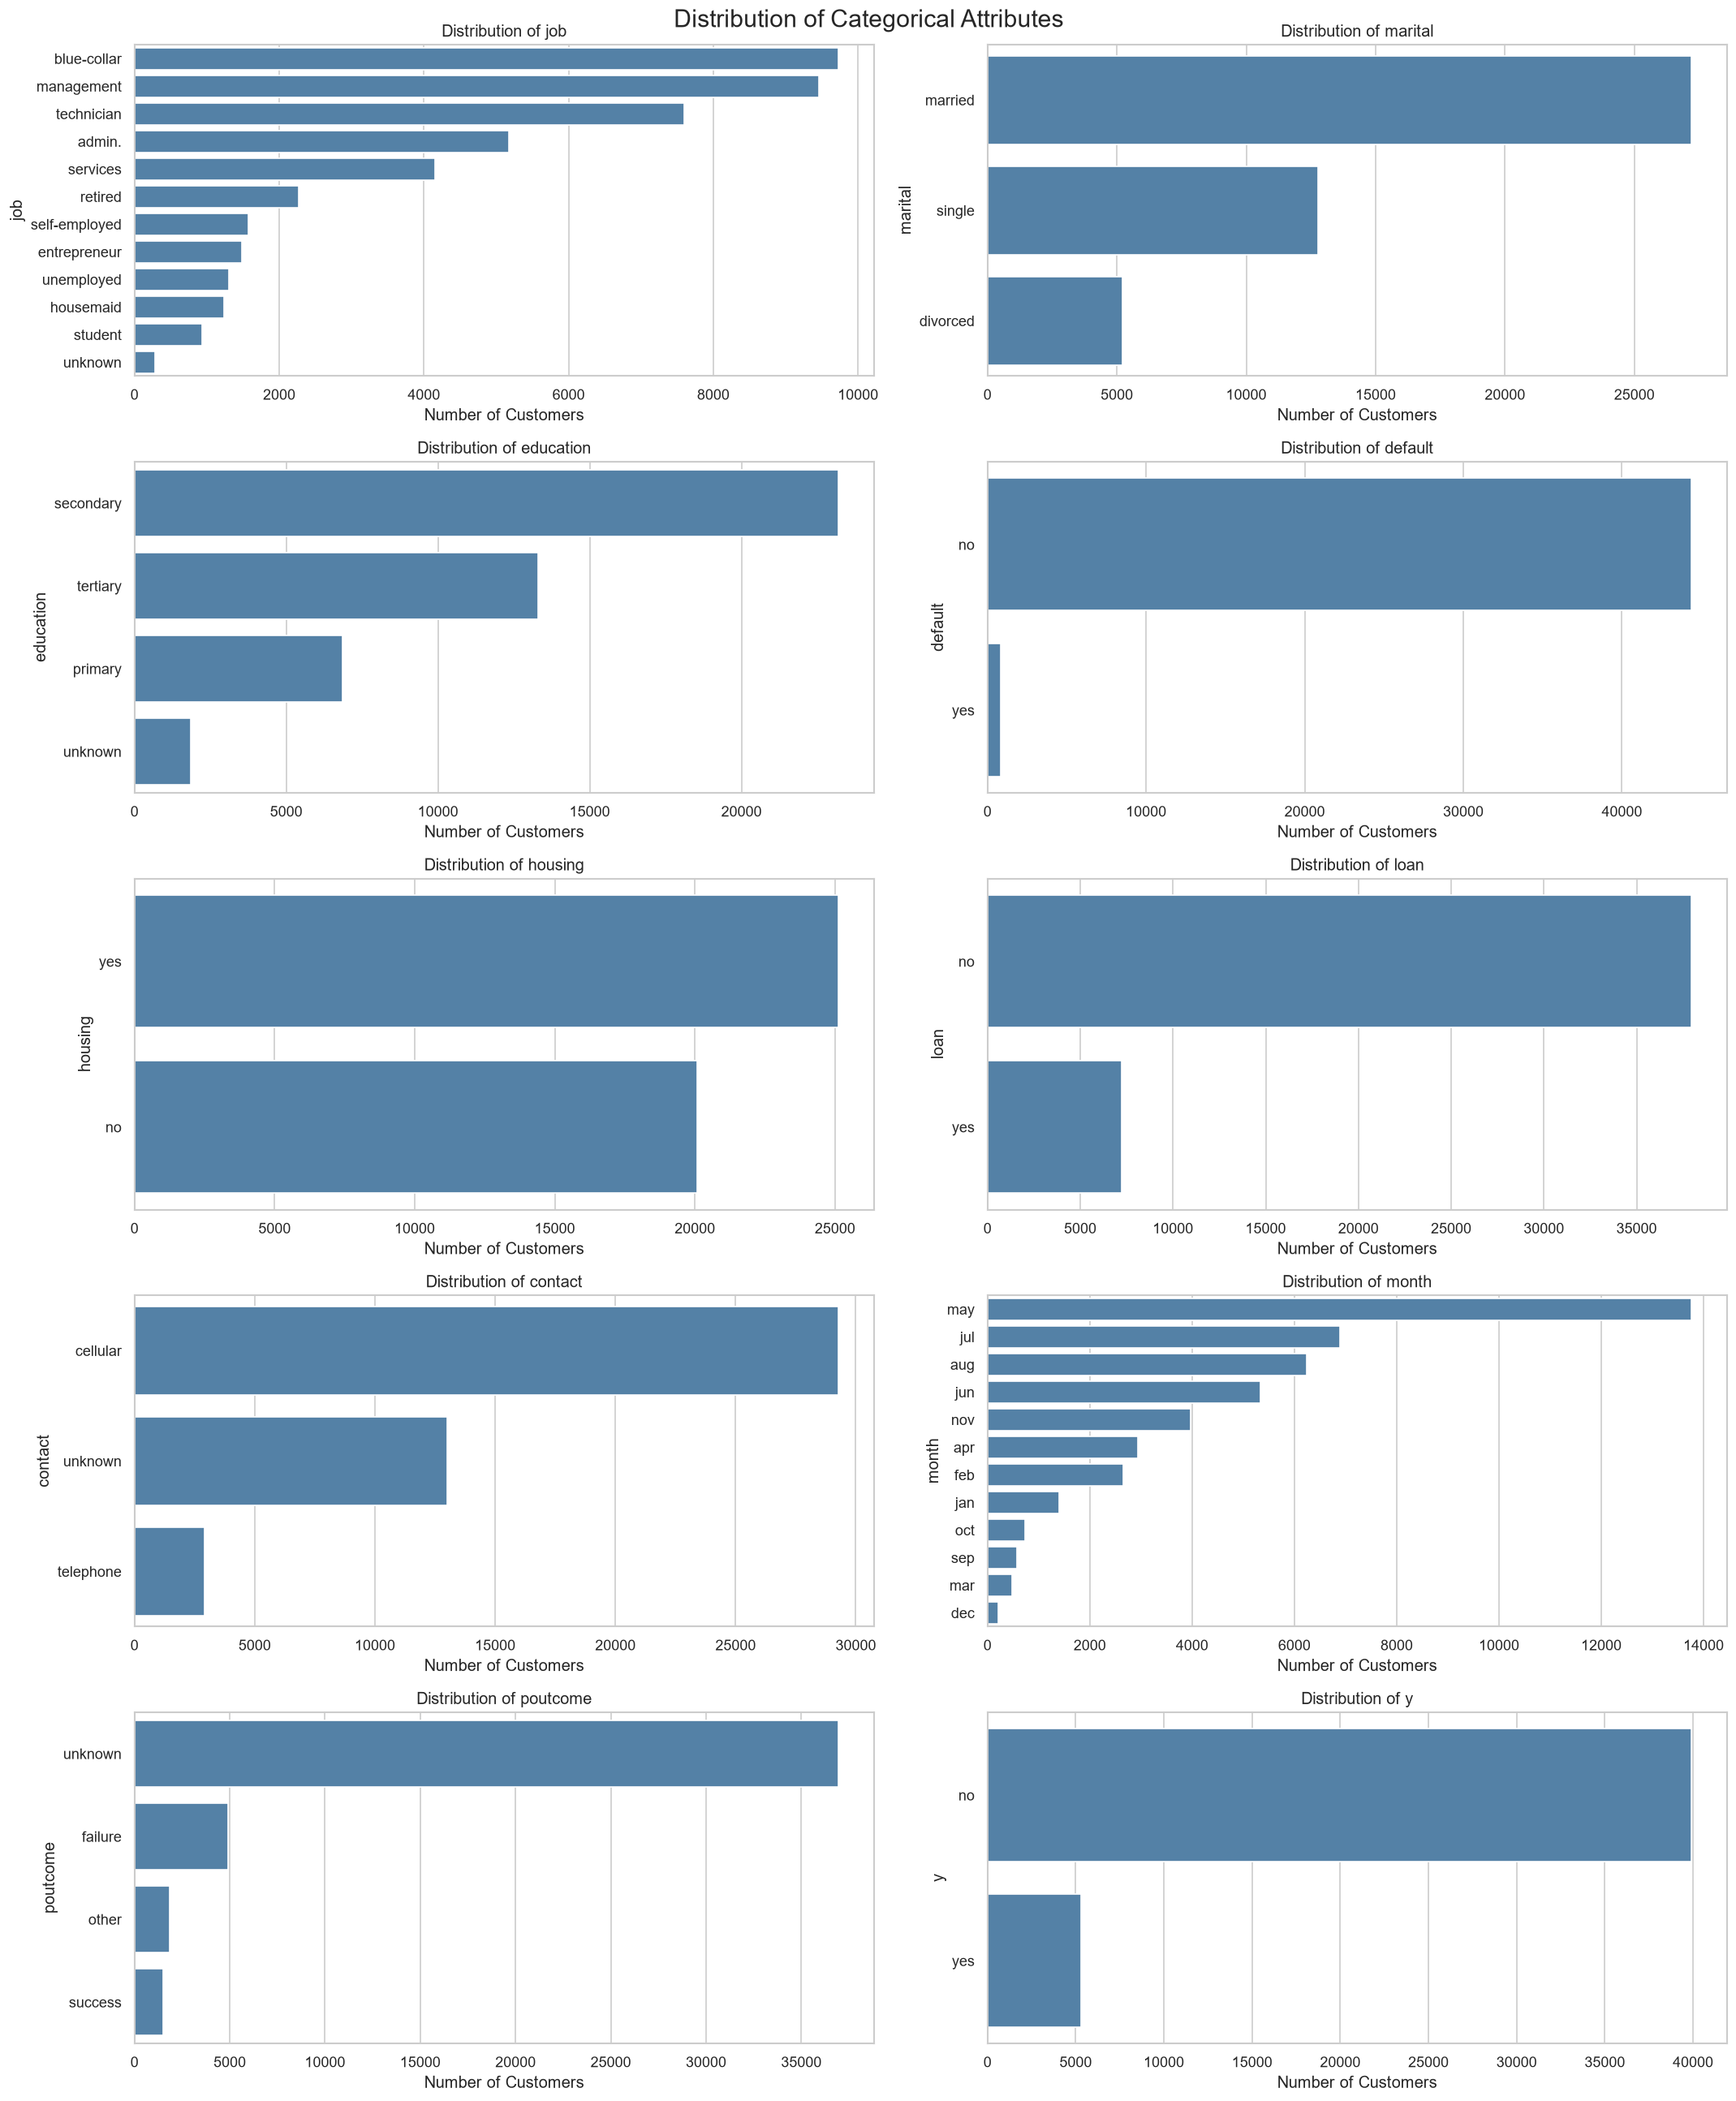

In [8]:
# ============================================================
# PHASE 1: OUTLIER ASSESSMENT AND CATEGORICAL DISTRIBUTIONS
# ============================================================

# 1. OUTLIER DETECTION USING THE IQR METHOD

outlier_results = []

for column in numerical_attributes:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Attribute": column,
        "Lower_Bound": round(lower_bound, 2),
        "Upper_Bound": round(upper_bound, 2),
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

print("NUMERICAL OUTLIER ASSESSMENT")
display(outlier_summary)

# 2. BOXPLOTS FOR NUMERICAL ATTRIBUTES

fig, axes = plt.subplots(3, 3, figsize=(17, 13))
axes = axes.flatten()

for i, column in enumerate(numerical_attributes):
    sns.boxplot(x=df[column], ax=axes[i])
    axes[i].set_title(f"Boxplot of {column}")

for j in range(len(numerical_attributes), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Outlier Inspection Across Numerical Attributes",
             fontsize=16)
plt.tight_layout()
plt.show()

# 3. CATEGORICAL ATTRIBUTE DISTRIBUTIONS

fig, axes = plt.subplots(5, 2, figsize=(18, 22))
axes = axes.flatten()

for i, column in enumerate(categorical_attributes):
    order = df[column].value_counts().index

    sns.countplot(
        data=df,
        y=column,
        order=order,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel("Number of Customers")
    axes[i].set_ylabel(column)

plt.suptitle("Distribution of Categorical Attributes",
             fontsize=18)
plt.tight_layout()
plt.show()

## Phase 2 — Relationships and exploratory findings

The next cells examine how categorical attributes relate to the subscription outcome. Cramér's V is used as a descriptive measure of association between two categorical variables. It does not establish causation.

In [ ]:
# Cramér's V association between each categorical predictor and the target.
from scipy.stats import chi2_contingency

association_rows = []
for column in categorical_attributes:
    if column == "y":
        continue
    contingency = pd.crosstab(df[column], df["y"])
    chi2 = chi2_contingency(contingency, correction=False)[0]
    n = contingency.to_numpy().sum()
    rows, cols = contingency.shape
    denominator = n * min(rows - 1, cols - 1)
    cramers_v = np.sqrt(chi2 / denominator) if denominator > 0 else np.nan
    association_rows.append({
        "Attribute": column,
        "Cramers_V": cramers_v,
        "Chi_square": chi2,
        "Degrees_of_freedom": (rows - 1) * (cols - 1)
    })

association_summary = (
    pd.DataFrame(association_rows)
    .sort_values("Cramers_V", ascending=False)
    .reset_index(drop=True)
)

print("Categorical association with subscription outcome")
display(association_summary.round(4))

# Subscription rate by category for selected attributes.
selected_categoricals = ["job", "education", "contact", "month", "poutcome"]
for column in selected_categoricals:
    rate = (
        df.groupby(column, observed=False)["y"]
        .apply(lambda values: (values == "yes").mean() * 100)
        .sort_values(ascending=False)
    )
    plt.figure(figsize=(10, 4))
    sns.barplot(x=rate.index, y=rate.values)
    plt.title(f"Term-deposit subscription rate by {column}")
    plt.xlabel(column)
    plt.ylabel("Subscription rate (%)")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

print("Interpretation reminder: these are descriptive group rates, not causal effects.")

## Phase 3 — Data preparation

The target is encoded as 1 for subscribers and 0 for non-subscribers. The feature `duration` is deliberately removed to avoid using information that would not be available before the call.

For `pdays`, the value -1 means the client was not previously contacted. We preserve that information in a separate binary feature and treat -1 as unavailable for the numeric days-since-contact field. Unknown categorical values are retained as explicit categories rather than silently discarded.

Imputation and one-hot encoding are placed inside a scikit-learn pipeline. This ensures that preprocessing is fitted on training folds only and helps prevent data leakage.

In [ ]:
# Prepare predictors and target.
model_df = df.copy()

model_df["previously_contacted"] = (model_df["pdays"] != -1).astype(int)
model_df["pdays"] = model_df["pdays"].replace(-1, np.nan)

y = model_df["y"].map({"no": 0, "yes": 1})
if y.isna().any():
    raise ValueError("Unexpected target labels found. Expected only 'yes' and 'no'.")

# Exclude target and duration to represent a pre-call prediction setting.
X = model_df.drop(columns=["y", "duration"])

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Predictor count:", X.shape[1])
print("Numeric predictors:", numeric_features)
print("Categorical predictors:", categorical_features)
print("Target distribution:")
display(y.value_counts().rename(index={0: "no", 1: "yes"}).to_frame("count"))

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print(f"Training observations: {X_train.shape[0]:,}")
print(f"Testing observations: {X_test.shape[0]:,}")
print("Stratified split completed.")

## Phase 4 — Decision Tree classification

A Decision Tree is used as the required data-mining classification technique. Class weighting is applied to make the model pay attention to the minority subscription class. The model is evaluated against a majority-class baseline.

The model is implemented as a single pipeline so that imputation, encoding, and classifier fitting happen together within each training split.

In [ ]:
# Majority-class baseline.
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)

# Decision Tree pipeline.
decision_tree = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=6,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ))
])

decision_tree.fit(X_train, y_train)
tree_predictions = decision_tree.predict(X_test)
tree_probabilities = decision_tree.predict_proba(X_test)[:, 1]

print("Baseline and Decision Tree models trained successfully.")

## Phase 5 — Model evaluation

Accuracy alone can be misleading because the target classes are imbalanced. We therefore report precision, recall, F1-score, ROC-AUC, and the confusion matrix. For this project, recall measures the proportion of actual subscribers identified by the model, while precision measures the proportion of predicted subscribers who actually subscribed.

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

def calculate_metrics(actual, predicted, probabilities=None):
    results = {
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1_score": f1_score(actual, predicted, zero_division=0)
    }
    results["ROC_AUC"] = (
        roc_auc_score(actual, probabilities)
        if probabilities is not None else np.nan
    )
    return results

evaluation = pd.DataFrame({
    "Majority baseline": calculate_metrics(y_test, baseline_predictions),
    "Decision Tree": calculate_metrics(y_test, tree_predictions, tree_probabilities)
}).T

print("Test-set performance comparison")
display(evaluation.round(4))

print("Decision Tree classification report")
print(classification_report(
    y_test, tree_predictions,
    target_names=["No subscription", "Subscription"],
    zero_division=0
))

cm = confusion_matrix(y_test, tree_predictions)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No subscription", "Subscription"]
).plot(values_format="d")
plt.title("Decision Tree — Test-set confusion matrix")
plt.tight_layout()
plt.show()

print("Confusion matrix (rows = actual, columns = predicted):")
display(pd.DataFrame(
    cm,
    index=["Actual no", "Actual yes"],
    columns=["Predicted no", "Predicted yes"]
))

## Phase 6 — Cross-validation and feature importance

Five-fold stratified cross-validation provides a more stable estimate of model performance across different training/validation partitions. Each fold refits the complete pipeline, including preprocessing.

Feature importance is extracted from the fitted Decision Tree. These values describe how the tree used encoded features; they should not be interpreted as causal effects.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = cross_validate(
    decision_tree,
    X, y,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

cv_summary = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean_validation_score": [
        cv_results[f"test_{metric}"].mean() for metric in scoring
    ],
    "Std_validation_score": [
        cv_results[f"test_{metric}"].std() for metric in scoring
    ],
    "Mean_training_score": [
        cv_results[f"train_{metric}"].mean() for metric in scoring
    ]
})

print("Five-fold stratified cross-validation")
display(cv_summary.round(4))

# Feature importance from the fitted pipeline.
feature_names = decision_tree.named_steps["preprocessor"].get_feature_names_out()
importances = decision_tree.named_steps["classifier"].feature_importances_

feature_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 15 Decision Tree feature importances")
display(feature_importance.head(15).round(4))

top_features = feature_importance.head(15).sort_values("Importance")
plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Decision Tree feature importances")
plt.xlabel("Importance")
plt.ylabel("Encoded feature")
plt.tight_layout()
plt.show()

## Phase 7 — Findings, limitations, and responsible use

Use the metric tables and charts generated above to write the final interpretation. Do not copy example scores from other projects: report the values produced by this notebook run.

### Interpretation points
- Compare the Decision Tree with the majority-class baseline, especially on recall, F1, and ROC-AUC.
- Identify the most important encoded features and explain that feature importance indicates model reliance, not causation.
- Consider the trade-off between finding more potential subscribers (recall) and the cost of contacting people who do not subscribe (precision).

### Limitations
- The target is imbalanced, so accuracy alone does not describe performance adequately.
- The `poutcome` field contains many unknown values; retaining this category preserves the information that the previous campaign outcome was not recorded.
- The data describes historical marketing activity and may not represent current customer behaviour.
- Random train/test splitting may not fully reflect performance on future campaigns.
- Associations and model feature importances do not establish causal relationships.

### Responsible use
The model should be treated as decision support, not as an automated decision-maker. Any deployment should include human oversight, privacy safeguards, fairness checks across relevant customer groups, monitoring for performance drift, and a review of the business costs of false positives and false negatives.

## Conclusion

Complete this paragraph after running all model cells: summarize whether the Decision Tree improves on the baseline, describe its key performance trade-offs, and state whether the results are useful enough for cautious campaign-planning support.

## References
1. Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing*. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306.
2. Scikit-learn documentation: https://scikit-learn.org/stable/

In [ ]:
# Automatically generated run summary for the project report.
print("DATA SUMMARY")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
print(f"Subscription prevalence: {(y.mean() * 100):.2f}%")
print("\nTEST-SET METRICS")
display(evaluation.round(4))
print("\nCROSS-VALIDATION")
display(cv_summary.round(4))
print("\nMOST IMPORTANT FEATURES")
display(feature_importance.head(10).round(4))
print("\nNotebook analysis completed.")